## **1 - Imports iniciais e armazenazenamento de base de dados .xlxs**

In [1]:
import pandas as pd
import numpy as np

from google.colab import files

arquivos = files.upload()

Saving base-dados-postup_revisada_sprint4_validacao(2).xlsx to base-dados-postup_revisada_sprint4_validacao(2).xlsx


## **2 - Leitura de planilhas na base**

In [2]:
arquivo = next(iter(arquivos))

excel = pd.ExcelFile(arquivo)

print("Abas encontradas:")
print(excel.sheet_names)

Abas encontradas:
['Validação', 'Postagem', 'Ações', 'Score', 'Impacto_Dificuldade']


## **3 - Leitura de dados das planilhas em específico**

In [5]:

# 3 - Leitura correta das abas da planilha

postagem = pd.read_excel(
    arquivo, sheet_name="Postagem", header=2
)

validacao = pd.read_excel(
    arquivo, sheet_name="Validação", header=2
)

score = pd.read_excel(
    arquivo, sheet_name="Score", header=2
)

impacto_dificuldade = pd.read_excel(
    arquivo, sheet_name="Impacto_Dificuldade", header=2
)

for nome, df in {
    "Postagem": postagem,
    "Validação": validacao,
    "Score": score,
    "Impacto_Dificuldade": impacto_dificuldade
}.items():
    print(f"\n--- {nome} ---")
    print("Dimensões:", df.shape)
    print("Colunas:", df.columns.tolist())
    display(df.head(3))



--- Postagem ---
Dimensões: (49, 10)
Colunas: ['ID', 'Texto', 'Categoria', 'Quantidade', 'Unidade', 'Data', 'Local', 'Frequência', 'Imagem', 'Vídeo']


,ID,Texto,Categoria,Quantidade,Unidade,Data,Local,Frequência,Imagem,Vídeo
0,P001,Hoje separei 5 kg de materiais recicláveis e l...,Reciclagem,5,kg,2026-08-25,São Paulo,1,sim,não
1,P002,Levei 4 pilhas usadas para um ponto de coleta ...,Reciclagem,4,unidades,2026-08-26,São Paulo,2,sim,não
2,P003,Reutilizei potes de vidro que eu tinha em casa...,Reutilização,5,unidades,2026-08-27,São Paulo,3,sim,não



--- Validação ---
Dimensões: (49, 8)
Colunas: ['ID', 'Duplicidade', 'Plágio', 'Indicador IA', 'Evidência Compativel', 'Veracidade', 'Origem do Registro', 'Classificação']


,ID,Duplicidade,Plágio,Indicador IA,Evidência Compativel,Veracidade,Origem do Registro,Classificação
0,P001,sim,não,não,sim,confirmada,Sintético,Duplicada
1,P002,não,não,não,sim,confirmada,Sintético,Legítima
2,P003,não,não,não,sim,confirmada,Sintético,Legítima



--- Score ---
Dimensões: (49, 9)
Colunas: ['Categoria', 'ID', 'Impacto', 'Frequência', 'Dificuldade', 'Confiabilidade', 'Score', 'Justificativa', 'Fonte']


,Categoria,ID,Impacto,Frequência,Dificuldade,Confiabilidade,Score,Justificativa,Fonte
0,Reciclagem,P001,65,14.2,85,60,62.42,A reciclagem possui benefícios ambientais comp...,US EPA
1,Reciclagem,P002,65,28.4,85,100,75.84,A reciclagem possui benefícios ambientais comp...,US EPA
2,Reutilização,P003,72,42.6,75,100,78.06,Redução na fonte e reutilização antes da recic...,US EPA



--- Impacto_Dificuldade ---
Dimensões: (19, 3)
Colunas: ['Categoria', 'Score_Impacto', 'Score_Dificuldade']


,Categoria,Score_Impacto,Score_Dificuldade
0,Ação Coletiva,87,50
1,Agricultura Sustentável,84,42
2,Biodiversidade,90,55


## **4 - Verificação inicial das planilhas. Ver se está tudo preenchido, se não tem id duplicado, etc**

In [6]:

# Validação inicial da base

bases = {
    "Postagem": postagem,
    "Validação": validacao,
    "Score": score,
    "Impacto_Dificuldade": impacto_dificuldade
}

for nome, df in bases.items():
    print(f"\n{'=' * 45}")
    print(f"BASE: {nome}")
    print(f"Registros: {len(df)}")
    print(f"Colunas: {list(df.columns)}")

    if "ID" in df.columns:
        print(f"IDs únicos: {df['ID'].nunique()}")
        print(f"IDs duplicados: {df['ID'].duplicated().sum()}")

    print("Valores ausentes por coluna:")
    print(df.isna().sum())

# Conferência dos IDs entre as três bases principais
ids_postagem = set(postagem["ID"].dropna())
ids_validacao = set(validacao["ID"].dropna())
ids_score = set(score["ID"].dropna())

print("\n===== CORRESPONDÊNCIA DOS IDS =====")
print("Postagens sem validação:", sorted(ids_postagem - ids_validacao))
print("Postagens sem score:", sorted(ids_postagem - ids_score))
print("Validações sem postagem:", sorted(ids_validacao - ids_postagem))
print("Scores sem postagem:", sorted(ids_score - ids_postagem))



BASE: Postagem
Registros: 49
Colunas: ['ID', 'Texto', 'Categoria', 'Quantidade', 'Unidade', 'Data', 'Local', 'Frequência', 'Imagem', 'Vídeo']
IDs únicos: 49
IDs duplicados: 0
Valores ausentes por coluna:
ID            0
Texto         0
Categoria     0
Quantidade    0
Unidade       0
Data          0
Local         0
Frequência    0
Imagem        0
Vídeo         0
dtype: int64

BASE: Validação
Registros: 49
Colunas: ['ID', 'Duplicidade', 'Plágio', 'Indicador IA', 'Evidência Compativel', 'Veracidade', 'Origem do Registro', 'Classificação']
IDs únicos: 49
IDs duplicados: 0
Valores ausentes por coluna:
ID                      0
Duplicidade             0
Plágio                  0
Indicador IA            0
Evidência Compativel    0
Veracidade              0
Origem do Registro      0
Classificação           0
dtype: int64

BASE: Score
Registros: 49
Colunas: ['Categoria', 'ID', 'Impacto', 'Frequência', 'Dificuldade', 'Confiabilidade', 'Score', 'Justificativa', 'Fonte']
IDs únicos: 49
IDs duplic

# **5 - MODELO DE TREINAMENTO 1 (VALIDAÇÕES - CLASSIFICAÇÃO)**

## **5.1 - Análise da classificação das postagens**

In [7]:

# MODELO 1 — ANÁLISE DA CLASSIFICAÇÃO DAS POSTAGENS

# Verificar as categorias de classificação
print("Classificações encontradas:")
print(validacao["Classificação"].value_counts())

# Verificar a proporção de cada classificação
print("\nProporção das classificações (%):")
print(
    (validacao["Classificação"].value_counts(normalize=True) * 100)
    .round(2)
)

# Visualizar alguns registros
display(validacao[["ID", "Classificação"]].head(10))


Classificações encontradas:
Classificação
Legítima            33
Suspeita             7
Duplicada            3
Plágio               3
Pouca Informação     2
Falsa                1
Name: count, dtype: int64

Proporção das classificações (%):
Classificação
Legítima            67.35
Suspeita            14.29
Duplicada            6.12
Plágio               6.12
Pouca Informação     4.08
Falsa                2.04
Name: proportion, dtype: float64


,ID,Classificação
0,P001,Duplicada
1,P002,Legítima
2,P003,Legítima
3,P004,Suspeita
4,P005,Legítima
5,P006,Suspeita
6,P007,Legítima
7,P008,Legítima
8,P009,Legítima
9,P010,Legítima


### **5.2 - Preparação dos dados para treinamento, separação em Entradas (x) e Respostas (y)**

In [8]:

# MODELO 1 — PREPARAÇÃO DOS DADOS

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
from sklearn.metrics import balanced_accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Separar as variáveis de entrada e a classificação desejada
colunas_entrada = [
    "Duplicidade",
    "Plágio",
    "Indicador IA",
    "Evidência Compativel",
    "Veracidade",
    "Origem do Registro"
]

X = validacao[colunas_entrada].copy()
y = validacao["Classificação"].copy()

# Garantir que os indicadores sejam tratados como categorias
X = X.astype("string")

print("Dimensões das entradas:", X.shape)
print("Quantidade de classificações:", y.nunique())
print("\nEntradas do modelo:")
display(X.head())

print("\nDistribuição das classes:")
print(y.value_counts())


Dimensões das entradas: (49, 6)
Quantidade de classificações: 6

Entradas do modelo:


,Duplicidade,Plágio,Indicador IA,Evidência Compativel,Veracidade,Origem do Registro
0,sim,não,não,sim,confirmada,Sintético
1,não,não,não,sim,confirmada,Sintético
2,não,não,não,sim,confirmada,Sintético
3,não,não,não,não,não confirmada,Sintético
4,não,não,não,sim,confirmada,Sintético



Distribuição das classes:
Classificação
Legítima            33
Suspeita             7
Duplicada            3
Plágio               3
Pouca Informação     2
Falsa                1
Name: count, dtype: int64


## **5.3 - Verificação de conexão entre indicador e classificação**

In [9]:
# Verificar como cada indicador se relaciona com a classificação final

for coluna in colunas_entrada:
    print(f"\n===== {coluna} =====")
    display(pd.crosstab(
        validacao[coluna],
        validacao["Classificação"]
    ))


===== Duplicidade =====


Classificação,Duplicada,Falsa,Legítima,Plágio,Pouca Informação,Suspeita
Duplicidade,,,,,,
não,0,1,33,3,2,7
sim,3,0,0,0,0,0



===== Plágio =====


Classificação,Duplicada,Falsa,Legítima,Plágio,Pouca Informação,Suspeita
Plágio,,,,,,
não,3,1,33,0,2,7
sim,0,0,0,3,0,0



===== Indicador IA =====


...

Classificação,Duplicada,Falsa,Legítima,Plágio,Pouca Informação,Suspeita
Evidência Compativel,,,,,,
não,0,1,0,3,2,7
sim,3,0,33,0,0,0



===== Veracidade =====


Classificação,Duplicada,Falsa,Legítima,Plágio,Pouca Informação,Suspeita
Veracidade,,,,,,
confirmada,3,0,33,3,0,0
não confirmada,0,1,0,0,2,7



===== Origem do Registro =====


Classificação,Duplicada,Falsa,Legítima,Plágio,Pouca Informação,Suspeita
Origem do Registro,,,,,,
Sintético,3,1,33,3,2,7


## **5.4 - Separação dos dados para treinamento e teste**

In [10]:
# Separar os dados em treino e teste
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

print("Quantidade de registros para treinamento:", len(X_treino))
print("Quantidade de registros para teste:", len(X_teste))

print("\nClasses presentes no treinamento:")
print(y_treino.value_counts())

print("\nClasses presentes no teste:")
print(y_teste.value_counts())

Quantidade de registros para treinamento: 36
Quantidade de registros para teste: 13

Classes presentes no treinamento:
Classificação
Legítima            22
Suspeita             5
Plágio               3
Duplicada            3
Pouca Informação     2
Falsa                1
Name: count, dtype: int64

Classes presentes no teste:
Classificação
Legítima    11
Suspeita     2
Name: count, dtype: int64


## **5.5 - Treinamento do RamdomForest**

Acurácia: 1.0
Acurácia balanceada: 1.0

Relatório de classificação:
                  precision    recall  f1-score   support

       Duplicada       0.00      0.00      0.00         0
           Falsa       0.00      0.00      0.00         0
        Legítima       1.00      1.00      1.00        11
          Plágio       0.00      0.00      0.00         0
Pouca Informação       0.00      0.00      0.00         0
        Suspeita       1.00      1.00      1.00         2

        accuracy                           1.00        13
       macro avg       0.33      0.33      0.33        13
    weighted avg       1.00      1.00      1.00        13



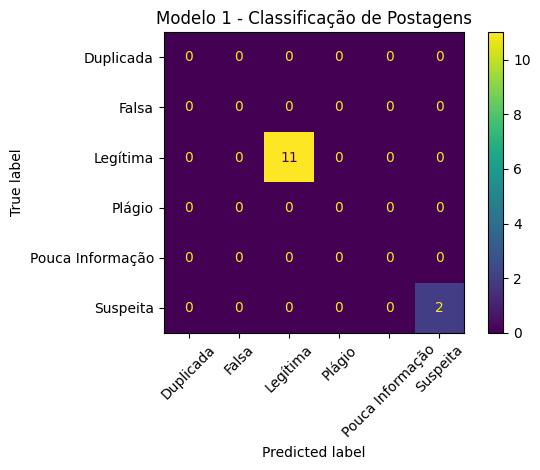

In [12]:
# Preparar o tratamento das variáveis categóricas
preprocessador = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            Pipeline(steps=[
                ("imputacao", SimpleImputer(strategy="most_frequent")),
                ("codificacao", OneHotEncoder(handle_unknown="ignore"))
            ]),
            colunas_entrada
        )
    ]
)

# Criar o modelo
modelo_validacao = Pipeline(steps=[
    ("preprocessador", preprocessador),
    ("classificador", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ))
])

# Treinar
modelo_validacao.fit(X_treino, y_treino)

# Fazer previsões
previsoes = modelo_validacao.predict(X_teste)

print("Acurácia:", round(accuracy_score(y_teste, previsoes), 4))
print(
    "Acurácia balanceada:",
    round(balanced_accuracy_score(y_teste, previsoes), 4)
)

print("\nRelatório de classificação:")
print(classification_report(
    y_teste,
    previsoes,
    labels=sorted(y.unique()),
    zero_division=0
))

# Gerar a matriz de confusão
ConfusionMatrixDisplay.from_predictions(
    y_teste,
    previsoes,
    labels=sorted(y.unique()),
    xticks_rotation=45
)

plt.title("Modelo 1 - Classificação de Postagens")
plt.tight_layout()
plt.show()

## **5.6 - Indicadores que o RamdomForest mais utilizou**

,Indicador,Importância
1,Duplicidade_sim,0.153928
0,Duplicidade_não,0.121289
6,Evidência Compativel_não,0.116394
7,Evidência Compativel_sim,0.108473
8,Veracidade_confirmada,0.104748
3,Plágio_sim,0.102219
9,Veracidade_não confirmada,0.095970
2,Plágio_não,0.083670
4,Indicador IA_não,0.061882
5,Indicador IA_sim,0.051426


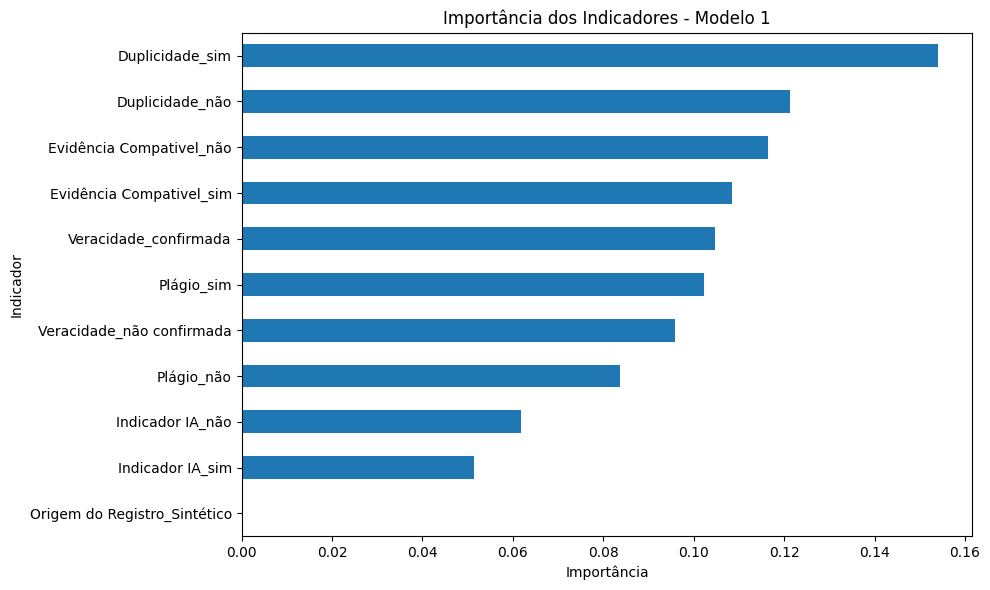

In [13]:
# Obter os nomes das variáveis após a codificação
nomes_indicadores = (
    modelo_validacao
    .named_steps["preprocessador"]
    .named_transformers_["categoricas"]
    .named_steps["codificacao"]
    .get_feature_names_out(colunas_entrada)
)

# Obter a importância de cada variável
importancias = (
    modelo_validacao
    .named_steps["classificador"]
    .feature_importances_
)

# Organizar da maior para a menor importância
importancia_indicadores = pd.DataFrame({
    "Indicador": nomes_indicadores,
    "Importância": importancias
}).sort_values("Importância", ascending=False)

display(importancia_indicadores)

# Criar gráfico
importancia_indicadores.plot(
    x="Indicador",
    y="Importância",
    kind="barh",
    legend=False,
    figsize=(10, 6)
)

plt.title("Importância dos Indicadores - Modelo 1")
plt.xlabel("Importância")
plt.ylabel("Indicador")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# **6 - MODELO DE TREINAMENTO 2 (SCORE - REGRESSÃO)**

## **6.1 - Preparando os dados**

In [14]:
# Modelo 2 - Preparação dos dados

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Selecionar os indicadores de entrada
colunas_score = [
    "Impacto",
    "Frequência",
    "Dificuldade",
    "Confiabilidade"
]

X_score = score[colunas_score].copy()
y_score = score["Score"].copy()

print("Quantidade de postagens:", len(score))
print("\nIndicadores utilizados:")
display(X_score.head())

print("\nValores de Score:")
display(y_score.head())

print("\nResumo dos indicadores:")
display(X_score.describe())

print("\nResumo do Score:")
display(y_score.describe())

print("\nValores ausentes nas entradas:")
print(X_score.isnull().sum())

print("\nValores ausentes no Score:")
print(y_score.isnull().sum())

Quantidade de postagens: 49

Indicadores utilizados:


,Impacto,Frequência,Dificuldade,Confiabilidade
0,65,14.2,85,60
1,65,28.4,85,100
2,72,42.6,75,100
3,68,56.8,88,20
4,70,71.0,78,100



Valores de Score:


,Score
0,62.42
1,75.84
2,78.06
3,56.48
4,80.70



Resumo dos indicadores:


,Impacto,Frequência,Dificuldade,Confiabilidade
count,49.000000,49.000000,49.000000,49.000000
mean,76.306122,29.583673,71.510204,79.591837
std,11.737057,26.288237,19.389777,32.529422
min,50.000000,14.200000,30.000000,0.000000
25%,65.000000,14.200000,55.000000,60.000000
50%,72.000000,14.200000,82.000000,100.000000
75%,87.000000,42.600000,85.000000,100.000000
max,94.000000,100.000000,90.000000,100.000000



Resumo do Score:


,Score
count,49.000000
mean,71.660408
std,11.301029
min,48.020000
25%,62.420000
50%,75.020000
75%,80.220000
max,86.800000



Valores ausentes nas entradas:
Impacto           0
Frequência        0
Dificuldade       0
Confiabilidade    0
dtype: int64

Valores ausentes no Score:
0


## **6.2 - Separação dos dados e treinamento do modelo**

In [15]:
# Modelo 2 - Divisão dos dados

X_score_treino, X_score_teste, y_score_treino, y_score_teste = train_test_split(
    X_score,
    y_score,
    test_size=0.25,
    random_state=42
)

print("Registros para treinamento:", len(X_score_treino))
print("Registros para teste:", len(X_score_teste))


# Criar o modelo de regressão
modelo_score = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Treinar o modelo
modelo_score.fit(X_score_treino, y_score_treino)

print("\nModelo de regressão treinado com sucesso!")

Registros para treinamento: 36
Registros para teste: 13

Modelo de regressão treinado com sucesso!


## **6.3 - Avaliar previsões do modelo com base no score**

In [16]:
# Modelo 2 - Avaliação do modelo

# Gerar previsões para os dados de teste
previsoes_score = modelo_score.predict(X_score_teste)

# Calcular as métricas
mae = mean_absolute_error(y_score_teste, previsoes_score)

rmse = mean_squared_error(
    y_score_teste,
    previsoes_score
) ** 0.5

r2 = r2_score(y_score_teste, previsoes_score)

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R²:", round(r2, 4))

# Comparar valores reais e previstos
comparacao_score = pd.DataFrame({
    "Score real": y_score_teste.values,
    "Score previsto": previsoes_score
})

comparacao_score["Erro absoluto"] = (
    comparacao_score["Score real"] -
    comparacao_score["Score previsto"]
).abs()

display(comparacao_score.round(2))

MAE: 2.66
RMSE: 3.77
R²: 0.8653


,Score real,Score previsto,Erro absoluto
0,86.80,78.12,8.68
1,50.22,50.40,0.18
2,74.42,75.05,0.63
3,73.42,79.71,6.29
4,80.48,82.68,2.20
5,52.22,53.60,1.38
6,73.42,79.71,6.29
7,78.22,77.19,1.03
8,74.42,75.05,0.63
9,74.42,75.05,0.63


## **6.4 - Gráfico para comparação de previsões e valores reais**

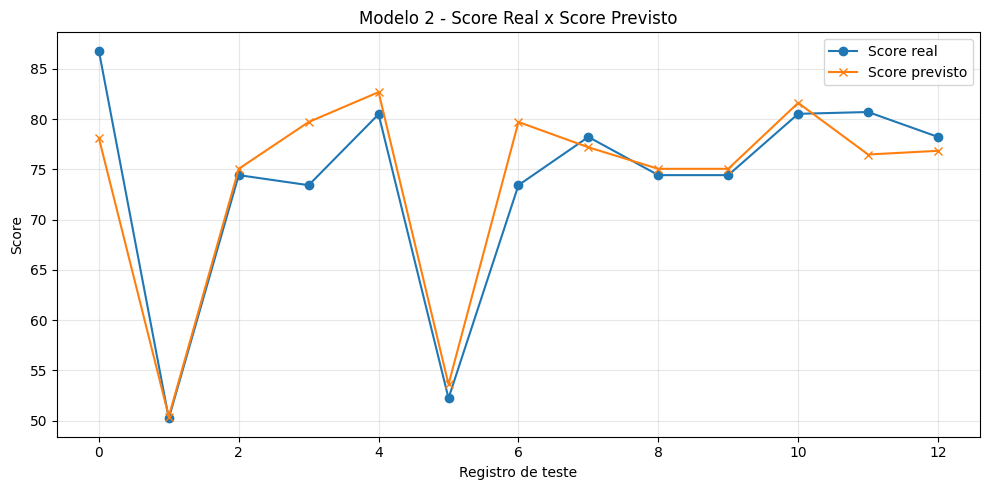

In [17]:
# Comparação entre Score real e previsto

plt.figure(figsize=(10, 5))

plt.plot(
    range(len(y_score_teste)),
    y_score_teste.values,
    marker="o",
    label="Score real"
)

plt.plot(
    range(len(previsoes_score)),
    previsoes_score,
    marker="x",
    label="Score previsto"
)

plt.title("Modelo 2 - Score Real x Score Previsto")
plt.xlabel("Registro de teste")
plt.ylabel("Score")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## **6.5 - Aplicação da fórmula de score definida na regras de negócio do Projeto**

In [18]:
# Conferir a fórmula original do Score

score["Score calculado"] = (
    score["Impacto"] * 0.4
    + score["Confiabilidade"] * 0.3
    + score["Dificuldade"] * 0.2
    + score["Frequência"] * 0.1
)

score["Diferença da fórmula"] = (
    score["Score"] - score["Score calculado"]
).abs()

print(
    "Maior diferença entre o Score da planilha e o calculado:",
    round(score["Diferença da fórmula"].max(), 4)
)

display(
    score[
        [
            "ID",
            "Impacto",
            "Frequência",
            "Dificuldade",
            "Confiabilidade",
            "Score",
            "Score calculado",
            "Diferença da fórmula"
        ]
    ].head(10).round(2)
)

Maior diferença entre o Score da planilha e o calculado: 0.0


,ID,Impacto,Frequência,Dificuldade,Confiabilidade,Score,Score calculado,Diferença da fórmula
0,P001,65,14.2,85,60,62.42,62.42,0.0
1,P002,65,28.4,85,100,75.84,75.84,0.0
2,P003,72,42.6,75,100,78.06,78.06,0.0
3,P004,68,56.8,88,20,56.48,56.48,0.0
4,P005,70,71.0,78,100,80.70,80.70,0.0
5,P006,72,85.2,90,20,61.32,61.32,0.0
6,P007,82,100.0,62,100,85.20,85.20,0.0
7,P008,92,14.2,30,100,74.22,74.22,0.0
8,P009,88,28.4,68,100,81.64,81.64,0.0
9,P010,94,42.6,45,100,80.86,80.86,0.0


## **6.6 - Comparando a fórmula original com o treinamento do RamdomForest**

In [19]:
# Comparar a fórmula original com o Random Forest
# usando os mesmos registros de teste

score_formula_teste = (
    X_score_teste["Impacto"] * 0.4
    + X_score_teste["Confiabilidade"] * 0.3
    + X_score_teste["Dificuldade"] * 0.2
    + X_score_teste["Frequência"] * 0.1
)

mae_formula = mean_absolute_error(
    y_score_teste,
    score_formula_teste
)

rmse_formula = mean_squared_error(
    y_score_teste,
    score_formula_teste
) ** 0.5

r2_formula = r2_score(
    y_score_teste,
    score_formula_teste
)

comparacao_modelos = pd.DataFrame({
    "Método": ["Fórmula original", "Random Forest"],
    "MAE": [
        mae_formula,
        mean_absolute_error(y_score_teste, previsoes_score)
    ],
    "RMSE": [
        rmse_formula,
        mean_squared_error(y_score_teste, previsoes_score) ** 0.5
    ],
    "R²": [
        r2_formula,
        r2_score(y_score_teste, previsoes_score)
    ]
})

display(comparacao_modelos.round(4))

,Método,MAE,RMSE,R²
0,Fórmula original,0.0000,0.000,1.0000
1,Random Forest,2.6633,3.766,0.8653


## **6.7 - Análise de importância dos quatro indicadores**

,Indicador,Importância
3,Confiabilidade,0.8943
0,Impacto,0.0510
2,Dificuldade,0.0444
1,Frequência,0.0103


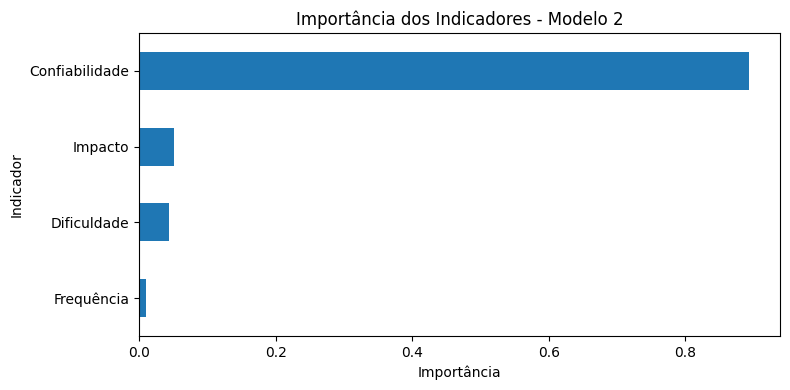

In [20]:
# Importância dos indicadores - Modelo 2

importancias_score = modelo_score.feature_importances_

importancia_score_df = pd.DataFrame({
    "Indicador": X_score.columns,
    "Importância": importancias_score
}).sort_values("Importância", ascending=False)

display(importancia_score_df.round(4))

importancia_score_df.plot(
    x="Indicador",
    y="Importância",
    kind="barh",
    legend=False,
    figsize=(8, 4)
)

plt.title("Importância dos Indicadores - Modelo 2")
plt.xlabel("Importância")
plt.ylabel("Indicador")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# 7 - Resumo, Conclusão e Discussões

# PostUp — Sprint 4: Modelos de Machine Learning

## 1. Introdução

Este documento apresenta o desenvolvimento e a avaliação de dois modelos de Machine Learning para o projeto PostUp. O objetivo é explorar a aplicação de técnicas de aprendizado de máquina na classificação de postagens e na estimativa de seus Scores.

Foram desenvolvidos dois modelos:

- **Modelo 1 — Classificação de postagens:** utiliza indicadores de validação para classificar cada postagem em uma das seis categorias definidas na base de dados.
- **Modelo 2 — Regressão do Score:** utiliza indicadores de impacto, frequência, dificuldade e confiabilidade para estimar o Score de uma postagem.

Os experimentos foram realizados em Python, utilizando o Google Colab, a biblioteca Pandas para manipulação dos dados e a biblioteca Scikit-learn para treinamento e avaliação dos modelos.

A base utilizada contém 49 postagens com dados sintéticos. Portanto, os resultados apresentados correspondem a um experimento inicial e não representam uma validação de publicações reais.

## 2. Base de dados e preparação

A base foi disponibilizada em uma planilha Excel, organizada em diferentes abas, incluindo `Postagem`, `Validação`, `Score` e `Impacto_Dificuldade`.

Antes do treinamento, foram realizadas as seguintes verificações:

- Leitura das planilhas com Pandas.
- Conferência das colunas e dos tipos de dados utilizados.
- Verificação de identificadores únicos.
- Conferência da correspondência entre postagens, validações e Scores.
- Verificação de valores ausentes.

Os resultados da preparação indicaram:

| Verificação | Resultado |
|---|---:|
| Quantidade de postagens | 49 |
| Registros de validação | 49 |
| Registros de Score | 49 |
| Identificadores duplicados nas tabelas verificadas | Nenhum |
| Valores ausentes nos campos utilizados | Nenhum |
| Postagens sem registro de validação ou Score correspondente | Nenhuma |

Os dados foram separados em conjuntos de treinamento e teste utilizando `train_test_split`, com `test_size=0.25` e `random_state=42`.

Assim, cada modelo foi treinado com 36 registros e avaliado com 13 registros.

## 3. Modelo 1 — Classificação de postagens

### 3.1. Objetivo

O primeiro modelo tem como objetivo classificar postagens com base em indicadores relacionados à sua validação.

As classes utilizadas são:

- `Legítima`
- `Suspeita`
- `Duplicada`
- `Plágio`
- `Pouca Informação`
- `Falsa`

### 3.2. Variáveis de entrada

Foram utilizadas as seguintes variáveis da planilha `Validação`:

- `Duplicidade`
- `Plágio`
- `Indicador IA`
- `Evidência Compativel`
- `Veracidade`
- `Origem do Registro`

A variável-alvo foi `Classificação`.

### 3.3. Algoritmo utilizado

Foi utilizado o algoritmo **Random Forest Classifier**, disponível no Scikit-learn.

O Random Forest combina diversas árvores de decisão para produzir uma classificação. Para o tratamento das variáveis categóricas, foi utilizado `OneHotEncoder`, dentro de um pipeline de pré-processamento e treinamento.

O modelo foi configurado com 100 árvores, `random_state=42` e `class_weight="balanced"`.

### 3.4. Resultados

No conjunto de teste, foram obtidos os seguintes resultados:

| Métrica | Resultado |
|---|---:|
| Acurácia | 1,0000 (100%) |
| Acurácia balanceada | 1,0000 (100%) |

A matriz de confusão apresentou:

| Classe real | Previsões corretas |
|---|---:|
| Legítima | 11 |
| Suspeita | 2 |
| **Total** | **13** |

Não foram observados erros entre as 13 postagens de teste.

Entretanto, o conjunto de teste continha somente as classes `Legítima` e `Suspeita`. As classes `Duplicada`, `Falsa`, `Plágio` e `Pouca Informação` não estavam representadas nesse conjunto.

Por esse motivo, não foi possível avaliar o desempenho do modelo nessas quatro classes por meio dessa divisão dos dados.

### 3.5. Importância dos indicadores

A análise de importância das variáveis do Random Forest apresentou os seguintes valores:

| Indicador | Importância |
|---|---:|
| `Duplicidade_sim` | 0,1539 |
| `Duplicidade_não` | 0,1213 |
| `Evidência Compativel_não` | 0,1164 |
| `Evidência Compativel_sim` | 0,1085 |
| `Veracidade_confirmada` | 0,1047 |
| `Plágio_sim` | 0,1022 |
| `Veracidade_não confirmada` | 0,0960 |
| `Plágio_não` | 0,0837 |
| `Indicador IA_não` | 0,0619 |
| `Indicador IA_sim` | 0,0514 |
| `Origem do Registro_Sintético` | 0,0000 |

A duplicidade apresentou a maior importância individual entre as variáveis codificadas. Os indicadores de evidência compatível e veracidade também apresentaram importâncias elevadas.

A origem do registro apresentou importância zero, pois todos os registros utilizados possuíam o valor `Sintético`, não oferecendo variação para distinguir as classes.

Essas importâncias descrevem como o modelo utilizou as variáveis durante o treinamento. Não representam causalidade nem comprovam que determinado indicador, isoladamente, seja suficiente para validar uma postagem.

## 4. Modelo 2 — Regressão do Score

### 4.1. Objetivo

O segundo modelo tem como objetivo estimar numericamente o Score das postagens com base em quatro indicadores.

Diferentemente do primeiro modelo, que prevê uma categoria, este modelo prevê um valor numérico contínuo.

### 4.2. Variáveis de entrada

Foram utilizadas as seguintes variáveis da planilha `Score`:

- `Impacto`
- `Frequência`
- `Dificuldade`
- `Confiabilidade`

A variável-alvo foi `Score`.

### 4.3. Fórmula original do Score

O Score utilizado no projeto é calculado pela seguinte fórmula:

\[
\text{Score} =
0{,}4I + 0{,}3C + 0{,}2D + 0{,}1F
\]

Em que:

- \(I\) representa o Impacto.
- \(C\) representa a Confiabilidade.
- \(D\) representa a Dificuldade.
- \(F\) representa a Frequência.

Os pesos são, respectivamente, 40%, 30%, 20% e 10%.

Antes de avaliar o modelo de regressão, a fórmula foi aplicada aos 49 registros da base. A maior diferença absoluta entre os Scores calculados e os valores existentes na planilha foi igual a zero.

Portanto, a fórmula reproduziu exatamente os 49 Scores utilizados no experimento.

### 4.4. Algoritmo utilizado

Foi utilizado o **Random Forest Regressor**, configurado com 100 árvores e `random_state=42`.

O modelo recebeu os quatro indicadores como entradas e aprendeu a estimar o Score com base nos exemplos do conjunto de treinamento.

### 4.5. Métricas de avaliação

No conjunto de teste, os resultados foram:

| Métrica | Resultado |
|---|---:|
| MAE | 2,6633 |
| RMSE | 3,7660 |
| R² | 0,8653 |

O **MAE (Mean Absolute Error)** representa o erro absoluto médio entre os valores previstos e reais. Nesse experimento, as previsões ficaram, em média, aproximadamente 2,66 pontos de Score distantes dos valores reais.

O **RMSE (Root Mean Squared Error)** penaliza mais fortemente os erros de maior magnitude. O valor de aproximadamente 3,77 indica que alguns erros maiores tiveram influência na avaliação.

O **R²** foi de 0,8653. Isso indica que, nessa amostra de teste, o modelo apresentou um ajuste relativamente bom em comparação com uma referência que prevê a média dos valores reais. Esse resultado não deve ser interpretado como uma taxa de acerto de 86,53%.

### 4.6. Comparação entre Scores reais e previstos

A comparação entre os 13 registros de teste mostrou que o modelo acompanhou razoavelmente as variações do Score real.

Alguns exemplos:

| Score real | Score previsto | Erro absoluto |
|---:|---:|---:|
| 86,80 | 78,12 | 8,68 |
| 50,22 | 50,40 | 0,18 |
| 74,42 | 75,05 | 0,63 |
| 73,42 | 79,71 | 6,29 |
| 80,48 | 82,68 | 2,20 |

O maior erro observado foi de 8,68 pontos. Por outro lado, houve previsões com diferenças inferiores a um ponto.

O gráfico de comparação entre Scores reais e previstos mostrou que as duas séries ficaram próximas em boa parte dos registros, embora algumas diferenças tenham sido mais acentuadas.

### 4.7. Importância dos indicadores

A importância das variáveis estimada pelo Random Forest Regressor foi:

| Indicador | Importância |
|---|---:|
| Confiabilidade | 0,8943 |
| Impacto | 0,0510 |
| Dificuldade | 0,0444 |
| Frequência | 0,0103 |

A Confiabilidade apresentou a maior importância estimada pelo modelo, representando aproximadamente 89,43% da importância total distribuída entre as variáveis.

Impacto e Dificuldade apresentaram importâncias menores, enquanto Frequência teve a menor importância estimada.

Essa distribuição não corresponde aos pesos oficiais da fórmula do Score. Na fórmula, Impacto tem peso de 40%, Confiabilidade de 30%, Dificuldade de 20% e Frequência de 10%.

A diferença ocorre porque a importância do Random Forest é estimada a partir dos padrões aprendidos nas divisões das árvores e depende da distribuição dos dados disponíveis. Ela não substitui os pesos definidos na regra original.

## 5. Discussão dos resultados

### 5.1. Discussão do Modelo 1

O Modelo 1 alcançou acurácia e acurácia balanceada de 100% no conjunto de teste. À primeira vista, esse resultado indica uma classificação correta de todas as postagens avaliadas.

Entretanto, a interpretação precisa considerar o tamanho reduzido da base e a distribuição das classes. Das 13 postagens de teste, 11 eram `Legítima` e duas eram `Suspeita`. Assim, o resultado não permite concluir que o modelo apresenta o mesmo desempenho nas seis classes.

Outro ponto importante é a relação entre os indicadores de entrada e a classificação final. Por exemplo, os três registros com `Duplicidade = sim` estavam classificados como `Duplicada`, e os três registros com `Plágio = sim` estavam classificados como `Plágio`. A evidência compatível e a veracidade também apresentaram associações fortes com determinadas classes.

Esses padrões podem facilitar o aprendizado do modelo, mas levantam a possibilidade de que os indicadores utilizados reproduzam diretamente as regras empregadas na criação dos rótulos. Se os rótulos foram definidos a partir desses mesmos indicadores, o modelo pode estar aprendendo essas regras em vez de identificar características independentes de uma postagem.

Portanto, o desempenho observado deve ser considerado preliminar. Uma avaliação mais robusta exigiria uma base maior, mais exemplos de cada classe e testes com registros independentes das regras usadas para produzir as classificações.

### 5.2. Discussão do Modelo 2

O Modelo 2 apresentou MAE de 2,6633, RMSE de 3,7660 e R² de 0,8653. Esses valores indicam que o Random Forest conseguiu aproximar os Scores da base, embora algumas previsões tenham apresentado diferenças relevantes.

A análise das previsões mostrou que os erros não foram uniformes. Algumas estimativas ficaram muito próximas dos valores reais, enquanto outras apresentaram diferenças de vários pontos. Isso demonstra que o desempenho varia conforme a combinação de indicadores encontrada pelo modelo.

A importância estimada da Confiabilidade foi muito superior à dos demais indicadores. Entretanto, a fórmula original atribui o maior peso a Impacto, com 40%, e não à Confiabilidade, cujo peso é 30%. Portanto, a importância do Random Forest não deve ser interpretada como uma descoberta de novos pesos oficiais para o Score.

A comparação direta com a fórmula original foi especialmente importante para interpretar esse resultado. Enquanto o Random Forest apresentou erros no conjunto de teste, a fórmula reproduziu exatamente os Scores da planilha, com MAE e RMSE iguais a zero e R² igual a 1,0000.

Isso ocorre porque o Score foi definido deterministicamente pela própria fórmula. Nesse cenário, utilizar um modelo de regressão para aproximar um valor que já pode ser calculado diretamente não oferece maior precisão do que aplicar a regra original.

O experimento continua sendo útil como demonstração do treinamento e da avaliação de um algoritmo de regressão. Entretanto, não demonstra que o Random Forest seja superior à fórmula, nem que consiga prever impactos ambientais reais.

### 5.3. Limitações gerais

Os resultados devem ser interpretados considerando as seguintes limitações:

1. **Tamanho da base:** os modelos utilizaram somente 49 registros, uma quantidade limitada para avaliar a generalização.
2. **Dados sintéticos:** os registros foram criados para o projeto e não constituem evidências coletadas de publicações reais.
3. **Distribuição das classes:** o Modelo 1 possui classes com poucos exemplos, incluindo apenas um registro da classe `Falsa` na base.
4. **Conjunto de teste reduzido:** a avaliação foi feita com 13 registros por modelo. No Modelo 1, somente duas das seis classes apareceram no teste.
5. **Possível dependência entre entradas e rótulos:** os indicadores de validação podem estar diretamente relacionados às regras que definiram a classificação final.
6. **Score determinístico:** o Score é calculado por uma fórmula conhecida, que reproduziu todos os valores da base sem diferença.
7. **Importância das variáveis:** os valores de importância do Random Forest descrevem o comportamento do modelo treinado e não devem ser confundidos com causalidade ou com os pesos oficiais do Score.

Uma evolução futura poderá utilizar mais registros, ampliar a representação de cada classe e avaliar os modelos em dados independentes. No caso do Score, uma nova abordagem de Machine Learning faria mais sentido se o objetivo fosse estimar um resultado que não pudesse ser calculado diretamente pela fórmula atual.

## 6. Conclusão

O Sprint 4 permitiu desenvolver dois experimentos de Machine Learning para o PostUp: um modelo de classificação de postagens e um modelo de regressão para estimar o Score.

O primeiro modelo classificou corretamente os 13 registros de teste, alcançando acurácia de 100%. No entanto, como somente duas classes estavam presentes no teste, ainda não é possível afirmar que o desempenho seja consistente em todas as categorias.

O segundo modelo apresentou MAE de 2,6633, RMSE de 3,7660 e R² de 0,8653, demonstrando capacidade de aproximar os Scores da amostra utilizada. A comparação com a fórmula original, porém, mostrou que a regra determinística continua sendo o método exato para calcular o Score atual.

Dessa forma, os experimentos demonstram a aplicação prática de classificação, regressão e avaliação de modelos com Scikit-learn, além de evidenciar a importância de interpretar as métricas considerando a qualidade e a quantidade dos dados.

Por fim, os resultados não comprovam a capacidade de validar publicações reais nem de medir diretamente impactos ambientais. Essas possibilidades exigiriam dados adequados, critérios verificáveis e avaliações adicionais antes de qualquer aplicação prática.


# **8 - Salvando os 2 modelos treinados**

In [21]:
import joblib

# Salvar o modelo de classificação
joblib.dump(
    modelo_validacao,
    "modelo_validacao_postup.joblib"
)

# Salvar o modelo de regressão
joblib.dump(
    modelo_score,
    "modelo_score_postup.joblib"
)

print("Modelos salvos com sucesso!")

Modelos salvos com sucesso!


In [22]:
from google.colab import files

files.download("modelo_validacao_postup.joblib")
files.download("modelo_score_postup.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>